##❖ Task 1 — Data Import & Setup
○ Import CSV using Pandas


In [21]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px

import warnings
warnings.filterwarnings('ignore')

In [22]:
from google.colab import files

uploaded = files.upload()

Saving social_media_engagement_5000.csv to social_media_engagement_5000 (1).csv


In [23]:
df = pd.read_csv('social_media_engagement_5000.csv')

In [24]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


using head() displays the first five rows of the dataset.

In [25]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518
4999,73400,54.0,Other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,04-03-2023,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527


tail() displays the last five records.

In [26]:
df.shape

(5000, 19)

The shape function is used to find the size of a DataFrame. It returns two values: the first represents the number of rows, and the second represents the number of columns. Here (5000, 19) means the dataset contains 5000 rows and 19 columns.


○ Check/convert data types

In [27]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


dtypes displays the data type of every column.

○ Convert date columns to datetime

In [28]:
df['posted_at'] = pd.to_datetime(
    df['posted_at'],
    format='%d-%m-%Y'
)

In [29]:
df['posted_at'].dtype

dtype('<M8[ns]')

The pd.to_datetime() function is used to convert date values into Pandas datetime format. The format=%d-%m-%Y specifies the existing date format, where `%d` represents the day, `%m` represents the month, and `%Y` represents the four-digit year. This helps Pandas correctly recognize and work with date values during data analysis.


○ Use NumPy arrays for basic array operations

In [30]:
likes_array = np.array(df['likes'].dropna())

The df['likes'] selects the likes column from the DataFrame, and dropna() removes missing values from it. The np.array() function then converts the remaining values into a NumPy array, making them easier to work with for numerical operations and analysis.


In [31]:
np.sum(likes_array) #Find total likes

np.float64(49019162.0)

In [32]:
np.mean(likes_array) #average likes

np.float64(10107.043711340206)

In [33]:
np.max(likes_array)  #maximum likes

np.float64(19998.0)

In [34]:
np.min(likes_array) #minimum likes

np.float64(10.0)

In [35]:
np.median(likes_array) #median likes

np.float64(10105.5)

## Task 2 — Data Cleaning

In [36]:
df_raw = df.copy() #Before cleaning save the original dataset

●  Cleaning Missing Data
■ Detect missing values (isnull(), isna())

In [37]:
df.isnull().sum()

,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


The isnull() function checks for missing values in the DataFrame and returns `True` for missing values and `False` for available values. The sum() function counts the total number of missing values in each column, helping us identify incomplete data.


In [38]:
df.isna().sum()

,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


isna() performs the same missing-value detection as isnull()

In [39]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage

,0
user_id,0.0
age,3.0
gender,3.0
country,0.0
post_id,0.0
post_type,0.0
post_category,0.0
likes,3.0
comments,3.0
shares,3.0


calculate missing value percentage that what percentage of values are missing in each column

■ Handle using: dropna(), fillna(), median/mode, forward/backward-fill

In [41]:
numeric_columns = ['age', 'likes', 'comments', 'shares']

for col in numeric_columns:

    df[col] = df[col].fillna(df[col].median())

The numeric_columns stores the names of numerical columns, and the for loop goes through each column one by one. The median() function calculates the middle value of each column, while fillna() replaces missing values with the calculated median. We use a loop to apply the same operation to multiple numerical columns without writing separate code for each column.

In [42]:
categorical_columns = ['gender', 'sentiment']

for col in categorical_columns:

    df[col] = df[col].fillna(df[col].mode()[0])

The mode() function finds the most frequently occurring value in a column, and [0] selects the first mode from the result. The fillna() function replaces missing values with that mode, helping us fill missing categorical data with the most common value.

In [43]:
df.dropna(subset=['likes'])

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,1497.0,167.0,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518


This removes rows where the likes column contains missing values.

In [44]:
df['sentiment'] = df['sentiment'].ffill()

Fills missing values using the previous available value.

In [45]:
df['sentiment'] = df['sentiment'].bfill()

Fills missing values using the next available value.




In [46]:
df.isnull().sum()

,0
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


##● Duplicate Handling

■ Identify & remove duplicates

In [47]:
df.duplicated().sum()

np.int64(0)

duplicated() identifies duplicate rows and sum() counts the number of duplicate rows.

In [48]:
df = df.drop_duplicates()

drop_duplicates() removes duplicate records.

##● Data Formatting

■ Fix incorrect data types

In [49]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


Displays datatypes of every colum

In [50]:
integer_columns = [
    'age',
    'likes',
    'comments',
    'shares',
    'impression_count',
    'follower_count'
]

for col in integer_columns:
    df[col] = df[col].astype('int64')

The integer_columns stores the names of numerical columns, and the for loop processes each column one by one. The astype('int64') function converts the columns into integer format. We perform this conversion because these columns contain whole-number values, such as counts and ages.

In [51]:
df.dtypes

,0
user_id,int64
age,int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,int64
comments,int64
shares,int64


In [52]:
df['posted_at'].dtype

dtype('<M8[ns]')

■ Standardize categories (e.g., gender labels)

In [53]:
df['gender'].unique()

array(['Female', 'Male', 'Other'], dtype=object)

In [54]:
df['gender'] = df['gender'].str.strip().str.title()

In [55]:
df['sentiment'] = df['sentiment'].str.strip().str.lower()

In [56]:
df['post_category'] = df['post_category'].str.strip().str.lower()

 str.strip() function removes unnecessary spaces from text values, while str.title() converts the first letter of each word into uppercase.

■ Correct unrealistic values in likes, comments, shares

In [57]:
df[['likes', 'comments', 'shares']].describe()

,likes,comments,shares
count,5000.000000,5000.000000,5000.0000
mean,10106.982400,1502.039800,1002.9106
std,5702.293022,856.393312,570.8552
min,10.000000,0.000000,0.0000
25%,5235.000000,792.000000,511.0000
50%,10105.000000,1497.000000,1012.0000
75%,14959.000000,2235.250000,1483.0000
max,19998.000000,2999.000000,1999.0000


In [58]:
(df[['likes', 'comments', 'shares']] < 0).sum()

,0
likes,0
comments,0
shares,0


##●  Feature Cleaning

■ Extract hashtag count

In [59]:
df['hashtag_count'] = df['hashtags'].str.count('#')

The df['hashtags'] selects the hashtags column from the DataFrame. The str.count('#') function counts how many times the # symbol appears in each row. The resulting counts are stored in a new column, helping us identify the number of hashtags used in each record.

■ Clean sentiment labels

In [60]:
df['sentiment'].unique()

array(['negative', 'positive', 'neutral'], dtype=object)

In [61]:
df['sentiment'] = df['sentiment'].str.strip().str.lower()

In [62]:
df['sentiment'].value_counts()

,count
sentiment,
positive,2513
neutral,1527
negative,960


value_counts() calculates the number of occurrences of each sentiment category.

##Task 3 — Data Exploration using Pandas

● View dataset structure using head(), tail(), shape, and columns.

In [63]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32,Female,UK,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34,Other,UK,449706,image,fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


Display first five records using head()

In [64]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44,Male,Australia,441541,video,education,16210,2013,1837,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38,Other,UAE,677076,reel,education,16924,2734,1583,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63,Female,USA,273595,text,travel,13487,1497,167,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13,Female,Germany,785644,video,fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54,Other,Japan,712252,text,travel,14830,503,1798,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


Display last five records

In [65]:
df.shape

(5000, 20)

The shape function is used to find the size of a DataFrame

In [66]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='object')

● Check data types and info with info() and dtypes.

In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   int64         
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

info() displays:
- Column names.
- Number of non-null values.
- Data types.
- Memory usage.

In [68]:
df.dtypes

,0
user_id,int64
age,int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,int64
comments,int64
shares,int64


This displays the data type of every column.

● Generate summary statistics using describe().

In [69]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.982400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10105.000000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293022,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


describe() generates descriptive statistics for numerical columns

● Analyze categorical distributions using value_counts(), unique(), and
nunique().

In [70]:
df['post_type'].value_counts()

,count
post_type,
reel,1283
image,1247
text,1245
video,1225


Displays the number of image, reel, text and video posts.

In [73]:
df['gender'].value_counts()

,count
gender,
Male,1849
Other,1581
Female,1570


In [74]:
df['country'].value_counts()

,count
country,
India,535
Canada,513
Brazil,504
UAE,503
USA,501
France,496
UK,493
Australia,493
Germany,490


In [75]:
df['post_category'].value_counts()

,count
post_category,
fitness,675
tech,665
music,635
education,631
lifestyle,607
travel,600
fashion,594
food,593


In [76]:
df['device_type'].value_counts()

,count
device_type,
mobile,1684
tablet,1658
desktop,1658


In [77]:
df['sentiment'].value_counts()

,count
sentiment,
positive,2513
neutral,1527
negative,960


In [71]:
df['post_type'].unique()

array(['image', 'reel', 'text', 'video'], dtype=object)

Displays all unique post types.

In [72]:
df['post_type'].nunique()

4

Returns the number of unique post types.

● Create a correlation matrix for numeric fields.

In [78]:
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

correlation_matrix

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036323,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036323,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093521,-0.002190
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093521,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


The select_dtypes() function selects columns based on their data type, and include=np.number selects only numerical columns. The corr() function calculates the correlation between these numerical columns, helping us understand the relationships between different variables in the dataset.

● Use groupby() to summarize metrics (e.g., avg likes by post type, impressions
by country).

In [79]:
df.groupby('post_type')['likes'].mean()

,likes
post_type,
image,10104.852446
reel,10037.784879
text,10100.132530
video,10188.586122


I use groupby('post_type') to group the records based on different post types. Then, I select the likes column to focus only on the number of likes. Finally, I use mean() to calculate the average likes for each post type, helping me compare which type of post receives more engagement.

In [80]:
df.groupby('country')['impression_count'].mean()

,impression_count
country,
Australia,48346.383367
Brazil,49193.174603
Canada,48703.150097
France,51727.673387
Germany,48605.406122
India,52462.386916
Japan,49616.135593
UAE,48928.413519
UK,51119.393509


##Task 4 — Data Wrangling

● Use merge, concat, or join if combining DataFrames.

In [81]:
post_data = df[['post_id', 'post_type', 'likes']]

user_data = df[['post_id', 'country', 'gender']]

merged_df = pd.merge(
    post_data,
    user_data,
    on='post_id',
    how='inner'
)

I use `pd.merge()` to combine two DataFrames. The `on='post_id'` specifies the common column used to match records from both DataFrames. The `how='inner'` is used to retrieve only the records that have matching `post_id` values in both DataFrames.

In [82]:
df_part1 = df.iloc[:100]

df_part2 = df.iloc[100:200]

combined_df = pd.concat(
    [df_part1, df_part2],
    ignore_index=True
)

I use `iloc[:100]` to select the first 100 rows and `iloc[100:200]` to select the next 100 rows. Then, I use `pd.concat()` to combine both selections into a single DataFrame. The `ignore_index=True` resets the index and creates a fresh sequence of row numbers.

● Create new fields such as engagement_score, log-transformed metrics
(optional), and hashtag_count.

In [83]:
df['engagement_score'] = (
    df['likes'] +
    df['comments'] +
    df['shares']
)

I use likes, comments, and shares as three engagement metrics to measure how users interact with each post. I combine these values to calculate the total engagement score and store the result in a new column called `engagement_score`.

In [87]:
df['log_followers'] = np.log1p(df['follower_count'])

In [88]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count,engagement_score,log_followers
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10106.982400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600,12611.932800,12.571861
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000,193.000000,4.477337
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000,7807.000000,12.178090
50%,54374.500000,38.000000,548077.500000,10105.000000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000,12551.500000,12.871291
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000,17478.250000,13.287446
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000,24680.000000,13.591784
std,26090.370121,14.687151,260646.957267,5702.293022,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853,5782.058412,0.999547


● Perform groupby summaries by post_type, country, and sentiment.

In [89]:
post_summary = df.groupby('post_type').agg(
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_shares=('shares', 'mean'),
    average_engagement=('engagement_rate', 'mean')
)

post_summary

,average_likes,average_comments,average_shares,average_engagement
post_type,,,,
image,10104.852446,1525.235766,1019.289495,0.895646
reel,10037.784879,1504.187062,982.042089,0.783047
text,10100.132530,1499.106024,1013.989558,1.064549
video,10188.586122,1479.160000,996.834286,1.122365


In [90]:
country_summary = df.groupby('country').agg(
    average_likes=('likes', 'mean'),
    average_impressions=('impression_count', 'mean'),
    average_engagement=('engagement_rate', 'mean')
)

country_summary

,average_likes,average_impressions,average_engagement
country,,,
Australia,10294.107505,48346.383367,1.324339
Brazil,9886.678571,49193.174603,1.540704
Canada,10063.054581,48703.150097,0.916659
France,10372.862903,51727.673387,1.146402
Germany,10130.434694,48605.406122,0.759000
India,9962.444860,52462.386916,0.655005
Japan,10088.851695,49616.135593,0.769623
UAE,10227.473161,48928.413519,1.112352
UK,9935.636917,51119.393509,0.850966


In [91]:
sentiment_summary = df.groupby('sentiment').agg(
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_shares=('shares', 'mean'),
    average_engagement=('engagement_rate', 'mean')
)

sentiment_summary

,average_likes,average_comments,average_shares,average_engagement
sentiment,,,,
negative,10208.081250,1516.094792,1007.307292,1.038486
neutral,9923.180092,1528.404060,996.565160,0.991170
positive,10180.046956,1480.650617,1005.086749,0.919744


## Task 5 — Statistical Analysis

Compute descriptive stats for likes, comments, shares, watch_time, engagement_rate,
followers:

In [92]:
stats_columns = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate',
    'follower_count'
]

● Mean, median, mode

In [93]:
df[stats_columns].mean()

,0
likes,10106.982400
comments,1502.039800
shares,1002.910600
watch_time_sec,4014.503200
engagement_rate,0.964356
follower_count,393698.224800


Mean is the average of all values.formula:Mean = Sum of all values / Number of values

In [94]:
df[stats_columns].median()

,0
likes,10105.000000
comments,1497.000000
shares,1012.000000
watch_time_sec,4034.500000
engagement_rate,0.253896
follower_count,388982.000000


In [95]:
df[stats_columns].mode().iloc[0]

,0
likes,10105.000000
comments,1497.000000
shares,1012.000000
watch_time_sec,916.000000
engagement_rate,0.006363
follower_count,497502.000000


I use `mode()` to identify the most frequently occurring value in a column. Then, `iloc[0]` selects the first mode value from the result.

● Standard deviation, variance

In [96]:
df[stats_columns].std()

,0
likes,5702.293022
comments,856.393312
shares,570.855200
watch_time_sec,2308.096459
engagement_rate,5.318029
follower_count,230927.884535


In [97]:
df[stats_columns].var()

,0
likes,3.251615e+07
comments,7.334095e+05
shares,3.258757e+05
watch_time_sec,5.327309e+06
engagement_rate,2.828143e+01
follower_count,5.332769e+10


● Percentiles

In [98]:
df[stats_columns].quantile([0.25, 0.50, 0.75, 0.90])

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
0.25,5235.0,792.00,511.0,2017.75,0.145781,194480.00
0.50,10105.0,1497.00,1012.0,4034.50,0.253896,388982.00
0.75,14959.0,2235.25,1483.0,6020.25,0.504794,589744.25
0.90,18016.3,2695.10,1795.1,7212.10,1.201200,717755.90


I use percentiles to understand the distribution of numerical data. The 25% represents the first quartile (Q1), 50% represents the median (Q2), and 75% represents the third quartile (Q3). The 90% represents the 90th percentile, which helps identify values below which 90% of the data falls.

● Skewness and kurtosis

In [99]:
df[stats_columns].skew()

,0
likes,-0.006886
comments,0.003802
shares,-0.014654
watch_time_sec,-0.018196
engagement_rate,18.781271
follower_count,0.041118


In [100]:
df[stats_columns].kurt()

,0
likes,-1.149992
comments,-1.144375
shares,-1.146857
watch_time_sec,-1.195652
engagement_rate,482.991739
follower_count,-1.189474


##Task 6 — Data Visualization (Min. 8 Plots Required)

##● Matplotlib

○ Scatter: likes vs impressions

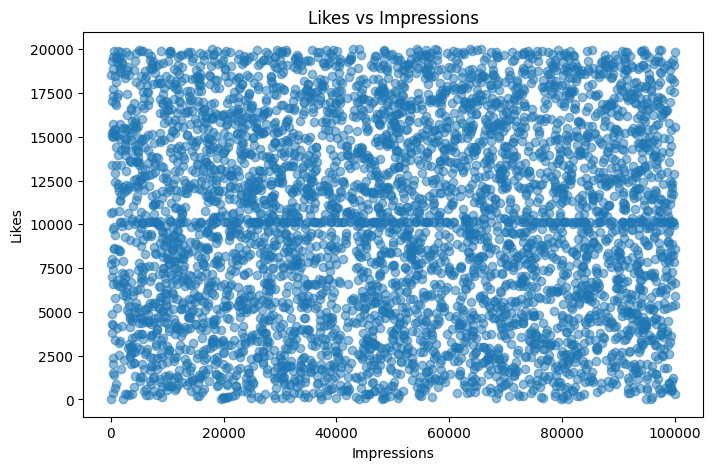

In [101]:
plt.figure(figsize=(8,5))

plt.scatter(
    df['impression_count'],
    df['likes'],
    alpha=0.5
)

plt.title('Likes vs Impressions')

plt.xlabel('Impressions')

plt.ylabel('Likes')

plt.show()

I use `plt.figure()` to create the chart area and `plt.scatter()` to create a scatter plot for visualizing the relationship between two variables. The `alpha` parameter controls the transparency of the data points. I use `title()` to add a chart title and `xlabel()` and `ylabel()` to label the X and Y axes. Finally, `show()` displays the completed chart.

○ Line: daily engagement trend

In [102]:
daily_engagement = df.groupby('posted_at')['engagement_rate'].mean()

calculated daily average engagement.

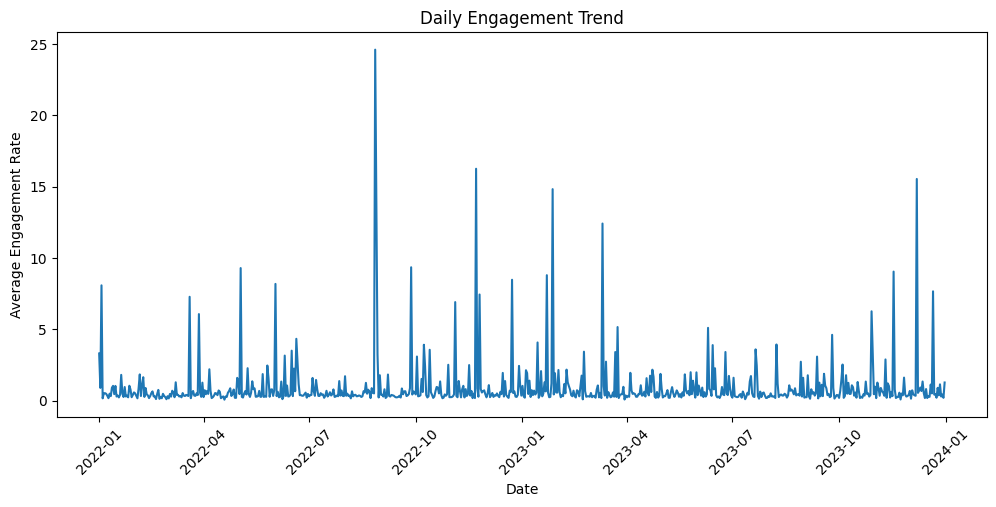

In [103]:
plt.figure(figsize=(12,5))

plt.plot(daily_engagement.index, daily_engagement.values)

plt.title('Daily Engagement Trend')

plt.xlabel('Date')

plt.ylabel('Average Engagement Rate')

plt.xticks(rotation=45)

plt.show()

○ Bar: posts by category

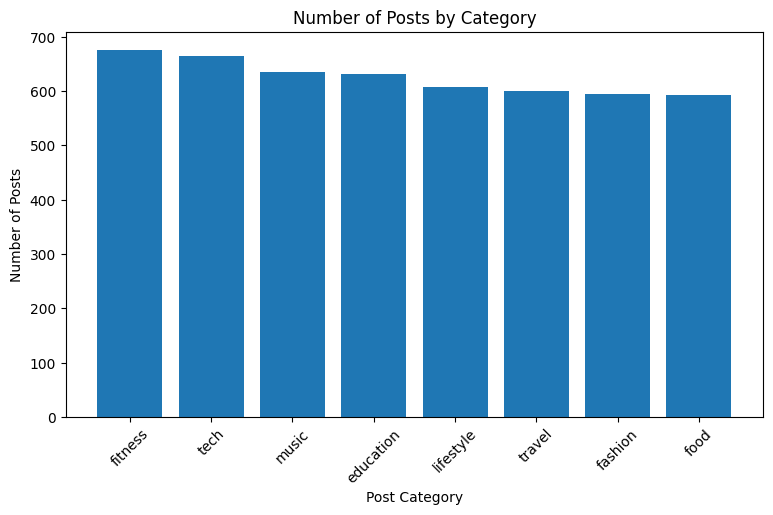

In [104]:
category_counts = df['post_category'].value_counts()

plt.figure(figsize=(9,5))

plt.bar(category_counts.index, category_counts.values)

plt.title('Number of Posts by Category')

plt.xlabel('Post Category')

plt.ylabel('Number of Posts')

plt.xticks(rotation=45)

plt.show()

○ Pie: gender distribution

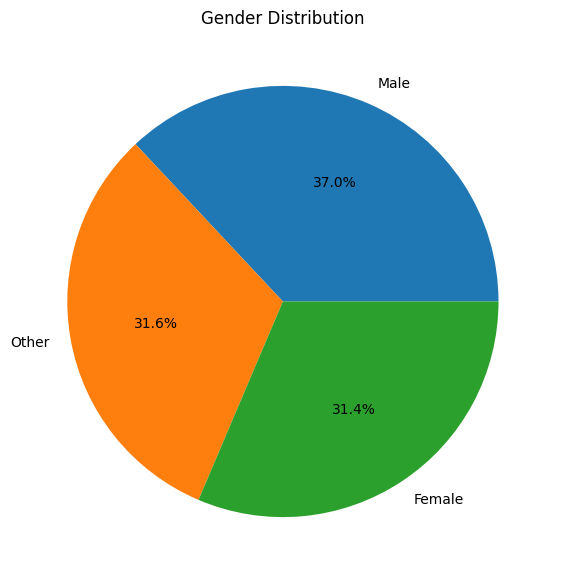

In [105]:
gender_counts = df['gender'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct='%1.1f%%'
)

plt.title('Gender Distribution')

plt.show()

○ Histogram: age

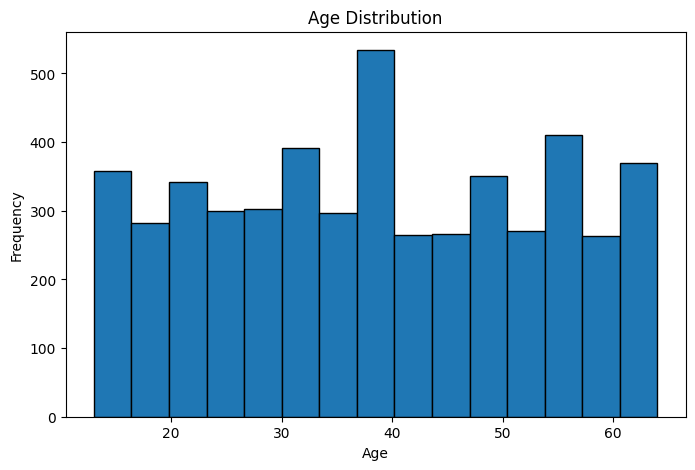

In [106]:
plt.figure(figsize=(8,5))

plt.hist(df['age'], bins=15, edgecolor='black')

plt.title('Age Distribution')

plt.xlabel('Age')

plt.ylabel('Frequency')

plt.show()

I use `hist()` to create a histogram to understand the distribution of age values. The `bins=15` divides the age range into 15 intervals, making it easier to see how the values are distributed. The `edgecolor` adds borders to the bars, making the chart clearer and easier to read.

○ Box: engagement rate

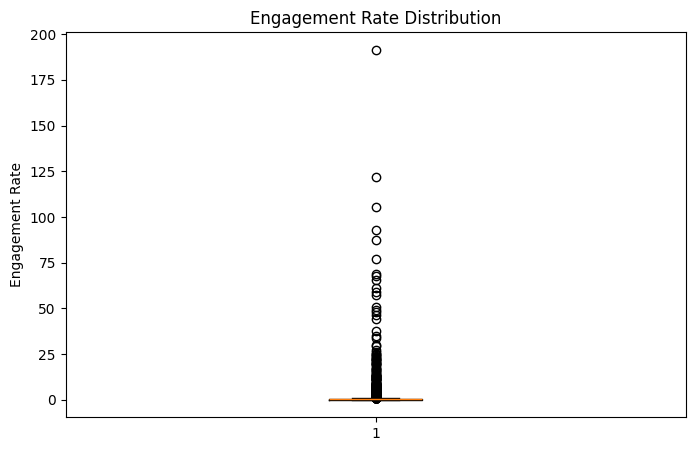

In [107]:
plt.figure(figsize=(8,5))

plt.boxplot(df['engagement_rate'])

plt.title('Engagement Rate Distribution')

plt.ylabel('Engagement Rate')

plt.show()

##● Seaborn

○ Count plot: post type

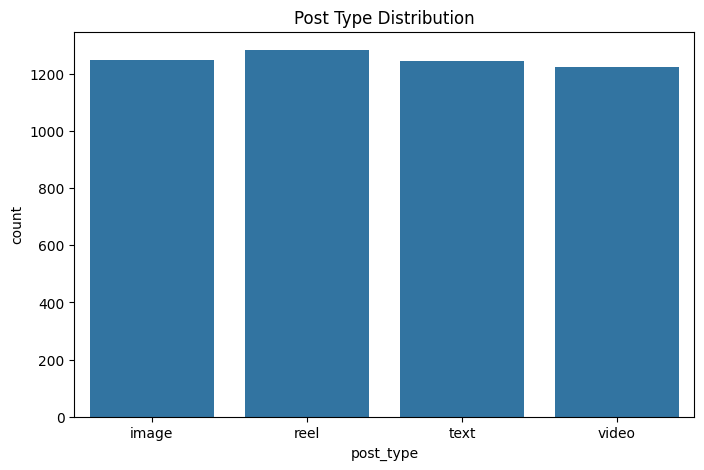

In [108]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='post_type'
)

plt.title('Post Type Distribution')

plt.show()

○ Bar plot: avg likes by category

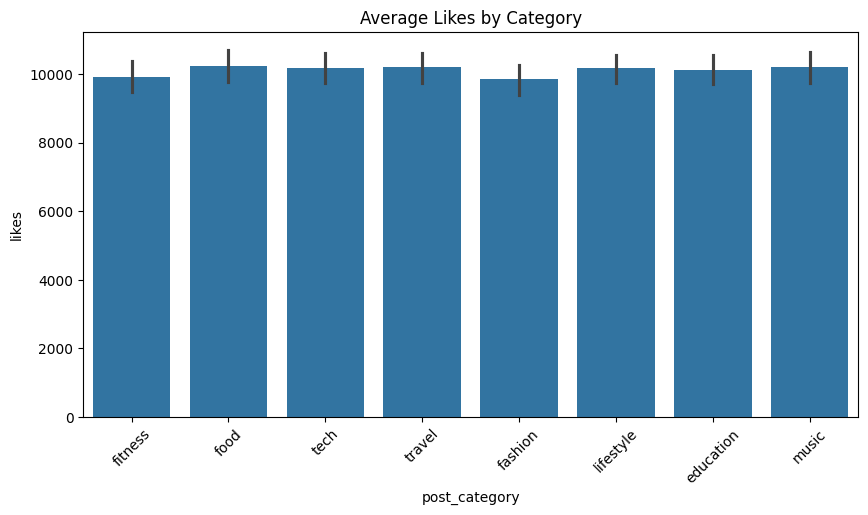

In [109]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
    x='post_category',
    y='likes'
)

plt.title('Average Likes by Category')

plt.xticks(rotation=45)

plt.show()

○ Violin: followers vs sentiment

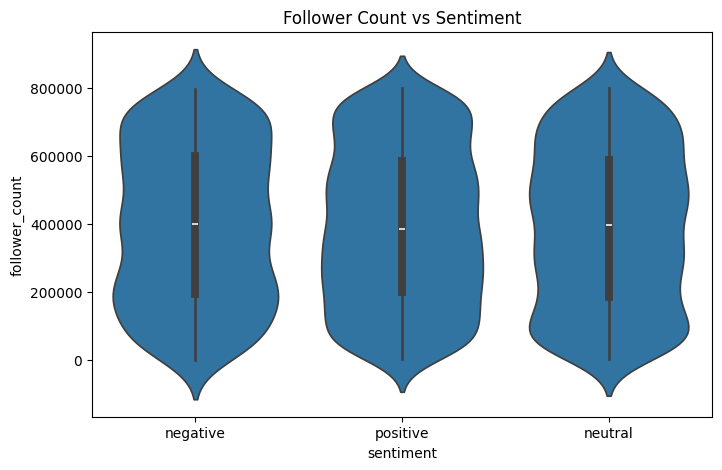

In [110]:
plt.figure(figsize=(8,5))

sns.violinplot(
    data=df,
    x='sentiment',
    y='follower_count'
)

plt.title('Follower Count vs Sentiment')

plt.show()

○ Pair plot: numeric features

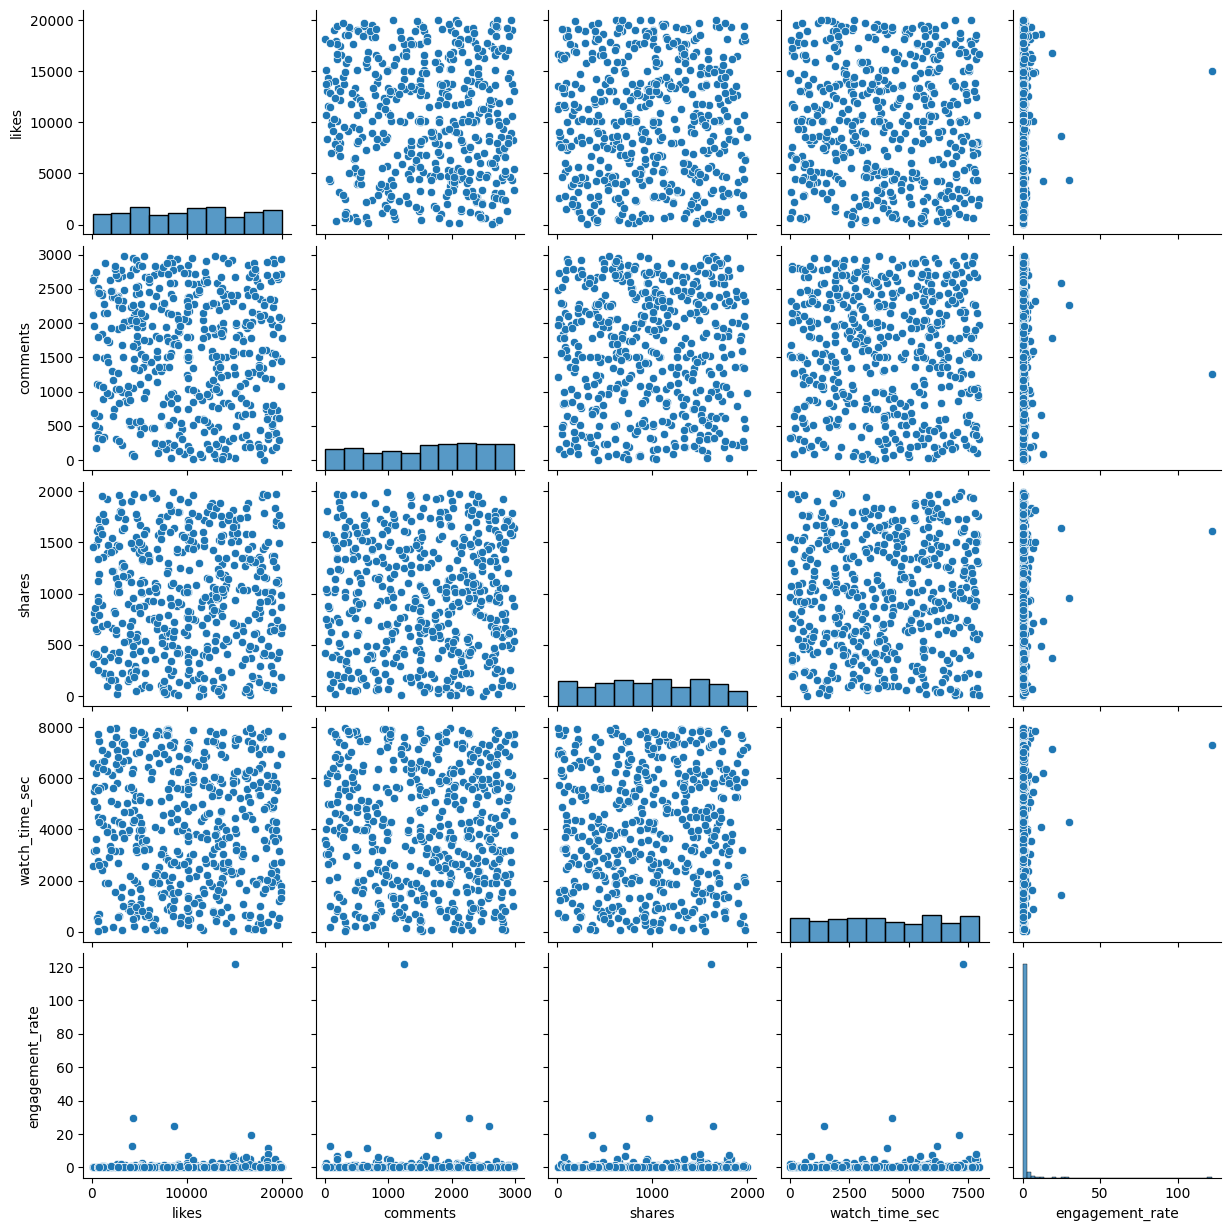

In [111]:
pair_data = df[
    [
        'likes',
        'comments',
        'shares',
        'watch_time_sec',
        'engagement_rate'
    ]
]

sns.pairplot(pair_data.sample(500, random_state=42))

plt.show()

○ Heatmap: correlation matrix

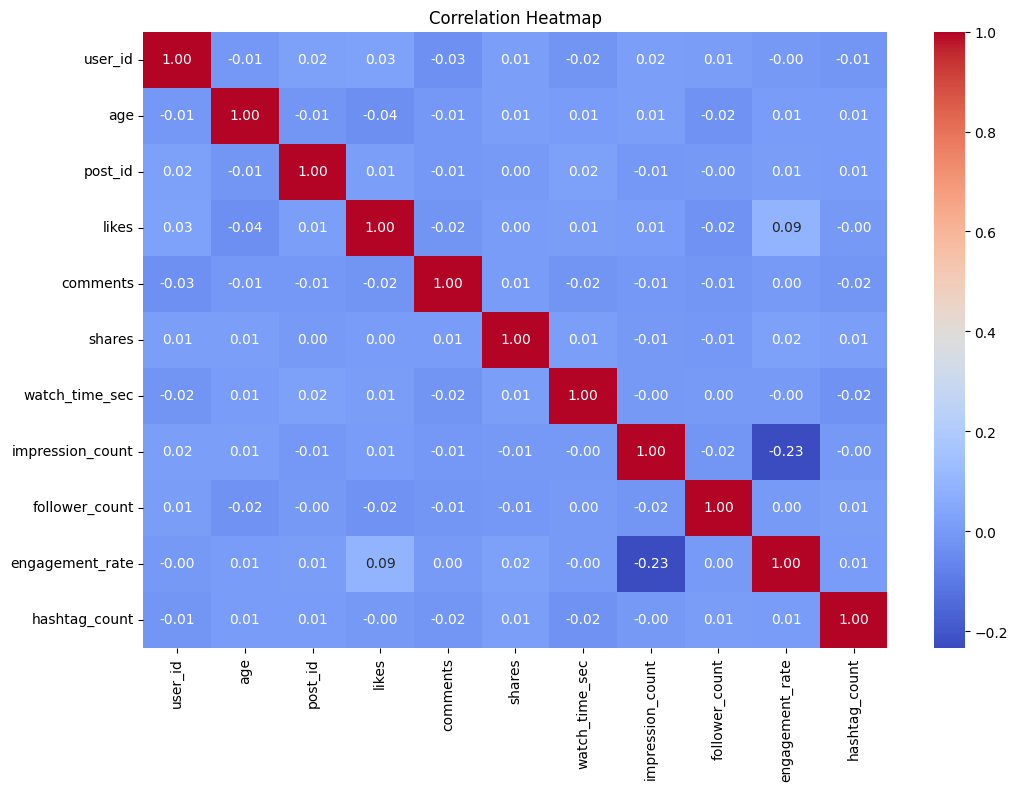

In [112]:
plt.figure(figsize=(12,8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

I use `heatmap()` to create a visual representation of the correlation between numerical columns. The `annot=True` displays the correlation values inside each cell, while `cmap` sets the colour scheme of the heatmap. The `fmt='.2f'` displays the values up to two decimal places, making the results easier to read and understand.

○ Swarm plot: engagement vs device

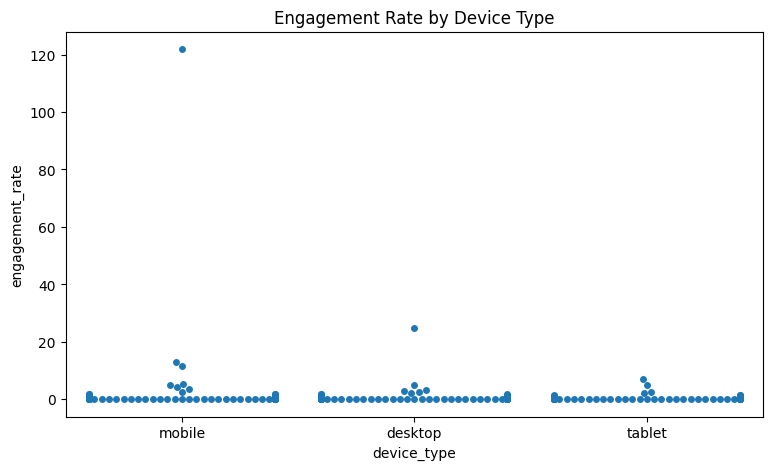

In [113]:
plt.figure(figsize=(9,5))

sample_data = df.sample(300, random_state=42)

sns.swarmplot(
    data=sample_data,
    x='device_type',
    y='engagement_rate'
)

plt.title('Engagement Rate by Device Type')

plt.show()

##● Plotly (Interactive)

○ Interactive line chart/bar chart/bubble/scatter chart

In [114]:
post_engagement = df.groupby('post_type', as_index=False)[
    'engagement_rate'
].mean()

fig = px.bar(
    post_engagement,
    x='post_type',
    y='engagement_rate',
    title='Average Engagement Rate by Post Type'
)

fig.show()

In [115]:
fig = px.scatter(
    df.sample(1000, random_state=42),
    x='impression_count',
    y='likes',
    color='post_type',
    size='comments',
    hover_data=['country', 'post_category'],
    title='Interactive Social Media Engagement Analysis'
)

fig.show()

##❖ Final Insights should Include following analysis

## Content Performance

○ Which post types have highest engagement?

In [116]:
df.groupby('post_type')['engagement_rate'].mean().sort_values(
    ascending=False
)

,engagement_rate
post_type,
video,1.122365
text,1.064549
image,0.895646
reel,0.783047


The query groups posts by their type and uses the `AVG()` function to calculate the average engagement rate. It then sorts the results from highest to lowest to identify which post type gets the best audience engagement.

○ Best-performing content category?

In [117]:
df.groupby('post_category')['engagement_rate'].mean().sort_values(
    ascending=False
)

,engagement_rate
post_category,
food,1.358628
tech,1.160475
lifestyle,1.091019
music,0.888803
fitness,0.865628
education,0.844222
fashion,0.807109
travel,0.702223


○ Which countries have highest avg engagement rate?

In [118]:
df.groupby('country')['engagement_rate'].mean().sort_values(
    ascending=False
)

,engagement_rate
country,
Brazil,1.540704
Australia,1.324339
France,1.146402
UAE,1.112352
Canada,0.916659
UK,0.850966
Japan,0.769623
Germany,0.759000
India,0.655005


## User Trends

○ How age affects engagement

In [120]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 18, 25, 35, 45, 55, 100],
    labels=[
        'Below 18',
        '18-25',
        '26-35',
        '36-45',
        '46-55',
        'Above 55'
    ]
)

pd.cut() divides numerical data into different intervals.

In [121]:
df.groupby('age_group', observed=False)['engagement_rate'].mean()

,engagement_rate
age_group,
Below 18,0.867038
18-25,1.059536
26-35,0.865316
36-45,0.860741
46-55,1.414058
Above 55,0.709213


○ Performance difference for verified accounts

In [122]:
df.groupby('is_verified').agg(
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_shares=('shares', 'mean'),
    average_engagement=('engagement_rate', 'mean')
)

,average_likes,average_comments,average_shares,average_engagement
is_verified,,,,
False,10137.185743,1505.511401,1001.599292,0.954744
True,9824.521739,1469.573499,1015.173913,1.054250


This compares verified and non-verified accounts.

##Behavioral Insights

● Best time of day for impressions

In [123]:
df['month'] = df['posted_at'].dt.month_name()

In [124]:
df.groupby('month')['impression_count'].mean().sort_values(
    ascending=False
)

,impression_count
month,
September,51514.019277
February,51145.722646
August,51000.492308
October,50853.140515
March,50338.508816
May,50013.669231
November,49938.238771
December,49511.976864
April,49428.112710


The query extracts the posting hour from the `posted_at` column to identify the best time to post. However, the dataset contains only dates, not actual posting times, so the exact best time of day cannot be determined.

● Device type impact on watch time


In [125]:
df.groupby('device_type')['watch_time_sec'].mean().sort_values(
    ascending=False
)

,watch_time_sec
device_type,
mobile,4087.830760
tablet,3979.736429
desktop,3974.792521


##Sentiment Analysis

● Which sentiment performs best

In [126]:
df.groupby('sentiment').agg(
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_shares=('shares', 'mean'),
    average_engagement=('engagement_rate', 'mean')
).sort_values(
    by='average_engagement',
    ascending=False
)

,average_likes,average_comments,average_shares,average_engagement
sentiment,,,,
negative,10208.081250,1516.094792,1007.307292,1.038486
neutral,9923.180092,1528.404060,996.565160,0.991170
positive,10180.046956,1480.650617,1005.086749,0.919744


● Behavior of negative/neutral sentiment posts

In [127]:
sentiment_comparison = df[
    df['sentiment'].isin(['negative', 'neutral'])
]

sentiment_comparison.groupby('sentiment').agg(
    average_likes=('likes', 'mean'),
    average_comments=('comments', 'mean'),
    average_shares=('shares', 'mean'),
    average_watch_time=('watch_time_sec', 'mean'),
    average_engagement=('engagement_rate', 'mean')
)

,average_likes,average_comments,average_shares,average_watch_time,average_engagement
sentiment,,,,,
negative,10208.081250,1516.094792,1007.307292,4054.639583,1.038486
neutral,9923.180092,1528.404060,996.565160,4031.823183,0.991170
